# Oráculo do ScribblePrompt: resolução e blocos

**Pergunta:** a imagem que entra no ScribblePrompt é reduzida de 1000² para 256² e chega pixelada (um núcleo mediano de 21 px
vira ~5 px). Aumentar a resolução da entrada, ou segmentar em **blocos** na resolução original, melhora a segmentação a partir
de marcadores conhecidos, sem fazer marcadores grandes vazarem?

| Modo | O que entra na rede | Núcleo mediano na entrada (40×) |
|---|---|---|
| `imagem 256²` | a imagem inteira reduzida para 256² (o pipeline atual) | ~5 px |
| `imagem 512²` | a imagem inteira reduzida para 512² | ~11 px |
| `imagem 1024²` | a imagem inteira, levemente ampliada para 1024² | ~22 px |
| `blocos 128 → 128²` | blocos de 128 × 128 px da imagem original, sem redução (128² é o tamanho de treino do ScribblePrompt) | ~21 px |
| `blocos 256 → 256²` | blocos de 256 × 256 px, sem redução | ~21 px |
| `blocos 256 → 128²` | blocos de 256 × 256 px reduzidos para 128² | ~11 px |

**Blocos:** sobreposição de 1/4 do lado; cada bloco recebe a sua parte da imagem e dos canais positivo e negativo, e as
probabilidades são combinadas por média ponderada com uma janela de Hann (peso menor perto da borda de cada bloco, onde a rede
vê menos contexto). É a estratégia de blocos sobrepostos usada pela U-Net e por ferramentas de inferência por janela deslizante.

Marcadores (do GT): `gt`, `miolo`, `centros`. Negativos: `zero` e `cp_fundo_r3` (pixels a mais de 3 px de qualquer máscara do
Cellpose). As definições são as do oráculo com negativo (`oraculo_negativo.ipynb`). Só as 37 imagens de treino; as três em 20×
aparecem separadas. Linha de base: Cellpose sozinho.

**Tudo é mostrado no notebook**; salvar é opcional (`SALVAR_RESULTADOS`). Com GPU, roda em poucos minutos; em CPU, leva horas.

## 0. Setup

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/Pedro-io/cell-fuzzy-seg.git"
BRANCH = "homolog"


def find_repo_root(start="."):
    p = os.path.abspath(start)
    prev = None
    while p != prev:
        if os.path.isdir(os.path.join(p, "src")) and os.path.exists(os.path.join(p, "pyproject.toml")):
            return p
        prev, p = p, os.path.dirname(p)
    return None


if "google.colab" in sys.modules:
    repo_root = os.path.join("/content", "cell-fuzzy-seg")
    if os.path.exists(repo_root):
        subprocess.run(["git", "-C", repo_root, "fetch", "origin", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "checkout", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "pull", "--ff-only", "origin", BRANCH], check=True)
    else:
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, repo_root], check=True)
else:
    repo_root = find_repo_root(os.getcwd())
    if repo_root is None:
        raise RuntimeError("Raiz do repositório não encontrada a partir do diretório atual.")

os.chdir(repo_root)
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
print("Repositório:", repo_root)
print(subprocess.run(["git", "log", "-1", "--oneline"], capture_output=True, text=True).stdout.strip())

Repositório: /content/cell-fuzzy-seg
3f9168d feat(diagnostico): notebook de diagnóstico dos marcadores aprendidos


In [2]:
if "google.colab" in sys.modules:
    get_ipython().system("python -m pip install -r requirements.txt -q")
else:
    print("Ambiente local: verifique se as dependências do requirements.txt estão instaladas.")

## 1. Configuração

In [3]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Patch
from scipy import ndimage
from skimage.segmentation import find_boundaries

from src.data.load.preprocessed_dataset import load_preprocessed
from src.evaluation.metrics import binary_metrics
from src.evaluation.report import provenance
from src.models.networks.final_segmentation.scribble_prompting_network import ScribblePromptingNetwork

NOME = "oraculo_resolucao"
SALVAR_RESULTADOS = False    # True: grava tabelas, figura e config em docs/estudo/resultados/<NOME>/
OUTPUT_DIR = os.path.join("docs", "estudo", "resultados", NOME)
MODELS_DIR = os.path.expanduser(os.path.join("~", "cell-fuzzy-models"))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Modo -> (lado do bloco em px da imagem original, ou None para a imagem inteira; tamanho da entrada da rede)
MODOS = {
    "imagem 256²": (None, 256),
    "imagem 512²": (None, 512),
    "imagem 1024²": (None, 1024),
    "blocos 128 → 128²": (128, 128),
    "blocos 256 → 256²": (256, 256),
    "blocos 256 → 128²": (256, 128),
}
SOBREPOSICAO = 0.25          # fração do lado do bloco compartilhada com o vizinho
BLOCOS_POR_LOTE = 16
LIMIARES = [0.5, 0.6, 0.7, 0.8]
IMAGENS_20X = {"TCGA-HE-7128-01Z-00-DX1", "TCGA-HE-7129-01Z-00-DX1", "TCGA-HE-7130-01Z-00-DX1"}

if DEVICE == "cpu":
    torch.set_num_threads(os.cpu_count())
print("Dispositivo:", DEVICE)

Dispositivo: cuda


## 2. Dados, marcadores e negativos

In [4]:
samples = load_preprocessed("train")
print(len(samples), "imagens")


def disco(raio):
    y, x = np.ogrid[-raio:raio + 1, -raio:raio + 1]
    return x * x + y * y <= raio * raio


def dilatar(mascara, raio):
    return ndimage.binary_dilation(mascara, structure=disco(raio)) if raio > 0 else mascara


def marcadores(sample):
    gt = sample["ground_truth"] > 0
    dmap = sample["distance_map"]
    return {
        "gt": gt,
        "miolo": gt & (dmap <= 0.5),
        "centros": dilatar(gt & (dmap <= 0.0), 4) & gt,
    }


def negativos(sample):
    cp = sample["cellpose_segmentation"] > 0
    return {"zero": np.zeros_like(cp), "cp_fundo_r3": ~dilatar(cp, 3)}

37 imagens


## 3. Segmentação pela imagem inteira e por blocos

In [5]:
checkpoint = ScribblePromptingNetwork.download_checkpoint(os.path.join(MODELS_DIR, "scribbleprompt"))
net = ScribblePromptingNetwork(checkpoint=checkpoint, device=DEVICE)


def inicios(n, bloco, passo):
    """Posições iniciais dos blocos ao longo de um eixo de tamanho n, cobrindo até a borda."""
    pos = list(range(0, n - bloco + 1, passo))
    if pos[-1] != n - bloco:
        pos.append(n - bloco)
    return pos


def janela_hann(bloco, piso=0.05):
    w = np.hanning(bloco)
    return np.maximum(np.outer(w, w), piso).astype(np.float32)


def segmentar(image, positivo, negativo, bloco, entrada):
    """Probabilidade (H, W) do ScribblePrompt; ``bloco=None`` usa a imagem inteira."""
    net.input_size = (entrada, entrada)
    scribbles = np.stack([positivo, negativo], axis=-1).astype(np.float32)
    if bloco is None:
        return net.predict({"image": image, "scribbles": scribbles})[0, 0].float().cpu().numpy()

    h, w = positivo.shape
    passo = int(bloco * (1 - SOBREPOSICAO))
    cantos = [(y, x) for y in inicios(h, bloco, passo) for x in inicios(w, bloco, passo)]
    peso = janela_hann(bloco)
    soma = np.zeros((h, w), np.float32)
    pesos = np.zeros((h, w), np.float32)
    for k in range(0, len(cantos), BLOCOS_POR_LOTE):
        lote = cantos[k:k + BLOCOS_POR_LOTE]
        imgs = np.stack([image[y:y + bloco, x:x + bloco] for y, x in lote])
        scr = np.stack([scribbles[y:y + bloco, x:x + bloco] for y, x in lote])
        probs = net.predict({"image": imgs, "scribbles": scr})[:, 0].float().cpu().numpy()
        for (y, x), p in zip(lote, probs):
            soma[y:y + bloco, x:x + bloco] += p * peso
            pesos[y:y + bloco, x:x + bloco] += peso
    return soma / pesos

Conferência: com a imagem inteira em 256², a função reproduz o oráculo com negativo (miolo do GT, sem negativo, limiar 0,5:
Dice médio 0,754 nas 37 imagens). Aqui, só a primeira imagem, para comparar com o valor dela no CSV daquele oráculo.

In [6]:
primeira = sorted(samples)[0]
s = samples[primeira]
m = marcadores(s)["miolo"]
d = binary_metrics(segmentar(s["image"], m, np.zeros_like(m), None, 256), s["ground_truth"])["dice"]
ref = os.path.join("docs", "estudo", "resultados", "oraculo_negativo", "por_imagem.csv.gz")
if os.path.exists(ref):
    r = pd.read_csv(ref)
    r = r[(r.id == primeira) & (r.marcador == "miolo") & (r.negativo == "zero") & (r.resolucao == 256)
          & (r.recorte_cellpose == "nenhum") & (r.limiar == 0.5)]
    print(f"{primeira}: Dice agora {d:.4f} | oráculo com negativo {float(r.dice.iloc[0]):.4f}")
else:
    print(f"{primeira}: Dice {d:.4f}")

TCGA-18-5592-01Z-00-DX1: Dice agora 0.7241 | oráculo com negativo 0.7241


## 4. Varredura

In [7]:
linhas = []
tempos = {modo: [] for modo in MODOS}
inicio = time.time()
for n, (image_id, s) in enumerate(samples.items(), start=1):
    gt = s["ground_truth"]
    base = binary_metrics(s["cellpose_segmentation"] > 0, gt)
    negs = negativos(s)
    for nome_m, positivo in marcadores(s).items():
        for nome_n, negativo in negs.items():
            for modo, (bloco, entrada) in MODOS.items():
                t = time.time()
                prob = segmentar(s["image"], positivo, negativo, bloco, entrada)
                tempos[modo].append(time.time() - t)
                for limiar in LIMIARES:
                    linhas.append({
                        "id": image_id, "aumento_20x": image_id in IMAGENS_20X, "marcador": nome_m,
                        "negativo": nome_n, "modo": modo, "limiar": limiar, **binary_metrics(prob, gt, limiar),
                        **{f"cellpose_{k}": v for k, v in base.items()},
                    })
    print(f"{n}/{len(samples)} {image_id} ({time.time() - inicio:.0f} s)", flush=True)

df = pd.DataFrame(linhas)
df["dif_dice"] = df["dice"] - df["cellpose_dice"]
print("Tempo médio por chamada (s):", {m: round(float(np.mean(t)), 2) for m, t in tempos.items()})

1/37 TCGA-18-5592-01Z-00-DX1 (12 s)
2/37 TCGA-21-5784-01Z-00-DX1 (24 s)
3/37 TCGA-21-5786-01Z-00-DX1 (37 s)
4/37 TCGA-38-6178-01Z-00-DX1 (50 s)
5/37 TCGA-49-4488-01Z-00-DX1 (64 s)
6/37 TCGA-50-5931-01Z-00-DX1 (77 s)
7/37 TCGA-A7-A13E-01Z-00-DX1 (89 s)
8/37 TCGA-A7-A13F-01Z-00-DX1 (102 s)
9/37 TCGA-AR-A1AK-01Z-00-DX1 (115 s)
10/37 TCGA-AR-A1AS-01Z-00-DX1 (127 s)
11/37 TCGA-AY-A8YK-01A-01-TS1 (140 s)
12/37 TCGA-B0-5698-01Z-00-DX1 (153 s)
13/37 TCGA-B0-5710-01Z-00-DX1 (166 s)
14/37 TCGA-B0-5711-01Z-00-DX1 (179 s)
15/37 TCGA-BC-A217-01Z-00-DX1 (192 s)
16/37 TCGA-CH-5767-01Z-00-DX1 (205 s)
17/37 TCGA-DK-A2I6-01A-01-TS1 (218 s)
18/37 TCGA-E2-A14V-01Z-00-DX1 (230 s)
19/37 TCGA-E2-A1B5-01Z-00-DX1 (243 s)
20/37 TCGA-F9-A8NY-01Z-00-DX1 (256 s)
21/37 TCGA-FG-A87N-01Z-00-DX1 (269 s)
22/37 TCGA-G2-A2EK-01A-02-TSB (282 s)
23/37 TCGA-G9-6336-01Z-00-DX1 (295 s)
24/37 TCGA-G9-6348-01Z-00-DX1 (308 s)
25/37 TCGA-G9-6356-01Z-00-DX1 (321 s)
26/37 TCGA-G9-6362-01Z-00-DX1 (334 s)
27/37 TCGA-G9-6363-01Z-00-DX

## 5. Resultados

Média por imagem; `dif_dice` = diferença pareada contra o Cellpose; `n_melhor` = imagens (de 37) em que a configuração supera
o Cellpose.

In [8]:
ORDEM_MODOS = list(MODOS)
cellpose = df.drop_duplicates("id")
print("Cellpose:", cellpose[["cellpose_dice", "cellpose_precision", "cellpose_recall", "cellpose_mass_ratio"]]
      .mean().round(3).to_dict())
pd.set_option("display.width", 200)
resumo = df.groupby(["marcador", "negativo", "modo", "limiar"]).agg(
    dice=("dice", "mean"), precisao=("precision", "mean"), revocacao=("recall", "mean"),
    massa=("mass_ratio", "mean"), dif_dice=("dif_dice", "mean"),
    n_melhor=("dif_dice", lambda d: int((d > 0).sum())),
).reset_index()
resumo_20x = df[df.aumento_20x].groupby(["marcador", "negativo", "modo", "limiar"])["dice"].mean().rename("dice_20x")
resumo = resumo.join(resumo_20x, on=["marcador", "negativo", "modo", "limiar"])


def tabela(valor, limiar=0.5):
    t = resumo[resumo.limiar == limiar].pivot_table(index=["marcador", "negativo"], columns="modo", values=valor)
    return t[ORDEM_MODOS]

Cellpose: {'cellpose_dice': 0.845, 'cellpose_precision': 0.867, 'cellpose_recall': 0.826, 'cellpose_mass_ratio': 0.955}


Dice no limiar 0,5 (linhas = marcador e negativo; colunas = modo):

In [9]:
tabela("dice").round(3)

modo                  imagem 256²  imagem 512²  imagem 1024²  blocos 128 → 128²  blocos 256 → 256²  blocos 256 → 128²
marcador negativo                                                                                                    
centros  cp_fundo_r3        0.786        0.769         0.825              0.684              0.669              0.795
         zero               0.542        0.672         0.732              0.315              0.311              0.751
gt       cp_fundo_r3        0.841        0.860         0.820              0.833              0.832              0.864
         zero               0.839        0.727         0.444              0.940              0.942              0.698
miolo    cp_fundo_r3        0.820        0.823         0.852              0.745              0.737              0.836
         zero               0.754        0.794         0.691              0.586              0.580              0.808

Massa (previsto / GT) no limiar 0,5. Acima de 1, a rede segmenta mais que o GT (vazamento):

In [10]:
tabela("massa").round(2)

modo                  imagem 256²  imagem 512²  imagem 1024²  blocos 128 → 128²  blocos 256 → 256²  blocos 256 → 128²
marcador negativo                                                                                                    
centros  cp_fundo_r3         0.91         0.84          0.96               0.99               0.95               0.87
         zero                0.43         0.59          1.53               0.20               0.19               0.75
gt       cp_fundo_r3         1.26         1.26          1.37               1.34               1.34               1.25
         zero                1.38         1.79          3.66               1.13               1.13               1.93
miolo    cp_fundo_r3         0.93         0.93          1.06               1.10               1.07               0.94
         zero                0.65         0.91          1.88               0.42               0.41               1.02

Precisão e revocação no limiar 0,5:

In [11]:
display(tabela("precisao").round(3))
tabela("revocacao").round(3)

modo                  imagem 256²  imagem 512²  imagem 1024²  blocos 128 → 128²  blocos 256 → 256²  blocos 256 → 128²
marcador negativo                                                                                                    
centros  cp_fundo_r3        0.832        0.852         0.846              0.704              0.704              0.862
         zero               0.939        0.920         0.635              0.995              0.996              0.889
gt       cp_fundo_r3        0.757        0.773         0.710              0.729              0.728              0.778
         zero               0.725        0.577         0.288              0.888              0.891              0.545
miolo    cp_fundo_r3        0.858        0.859         0.829              0.719              0.722              0.867
         zero               0.963        0.870         0.560              0.992              0.994              0.839

modo                  imagem 256²  imagem 512²  imagem 1024²  blocos 128 → 128²  blocos 256 → 256²  blocos 256 → 128²
marcador negativo                                                                                                    
centros  cp_fundo_r3        0.753        0.708         0.811              0.683              0.656              0.745
         zero               0.397        0.539         0.902              0.196              0.193              0.659
gt       cp_fundo_r3        0.948        0.970         0.972              0.974              0.973              0.973
         zero               0.997        1.000         1.000              1.000              1.000              1.000
miolo    cp_fundo_r3        0.792        0.793         0.877              0.782              0.764              0.810
         zero               0.622        0.747         0.957              0.416              0.410              0.801

Melhor limiar de cada configuração (o limiar é escolhido nas mesmas imagens, então o valor é um pouco otimista):

In [12]:
melhores = resumo.loc[resumo.groupby(["marcador", "negativo", "modo"])["dice"].idxmax()]
display(melhores.pivot_table(index=["marcador", "negativo"], columns="modo", values="dice")[ORDEM_MODOS].round(3))
melhores.pivot_table(index=["marcador", "negativo"], columns="modo", values="n_melhor")[ORDEM_MODOS]

modo                  imagem 256²  imagem 512²  imagem 1024²  blocos 128 → 128²  blocos 256 → 256²  blocos 256 → 128²
marcador negativo                                                                                                    
centros  cp_fundo_r3        0.786        0.769         0.825              0.684              0.669              0.795
         zero               0.542        0.672         0.745              0.315              0.311              0.751
gt       cp_fundo_r3        0.878        0.887         0.858              0.881              0.882              0.890
         zero               0.915        0.849         0.493              0.984              0.985              0.828
miolo    cp_fundo_r3        0.820        0.823         0.852              0.745              0.737              0.836
         zero               0.754        0.794         0.746              0.586              0.580              0.808

modo                  imagem 256²  imagem 512²  imagem 1024²  blocos 128 → 128²  blocos 256 → 256²  blocos 256 → 128²
marcador negativo                                                                                                    
centros  cp_fundo_r3          0.0          0.0           3.0                0.0                0.0                0.0
         zero                 0.0          1.0           1.0                0.0                0.0                2.0
gt       cp_fundo_r3         34.0         37.0          26.0               34.0               34.0               37.0
         zero                37.0         25.0           0.0               37.0               37.0               22.0
miolo    cp_fundo_r3          2.0          3.0          27.0                0.0                0.0                9.0
         zero                 2.0          7.0           5.0                0.0                0.0               14.0

Imagens em 20× (Dice no limiar 0,5; nas outras 34 imagens, ver a primeira tabela):

In [13]:
tabela("dice_20x").round(3)

modo                  imagem 256²  imagem 512²  imagem 1024²  blocos 128 → 128²  blocos 256 → 256²  blocos 256 → 128²
marcador negativo                                                                                                    
centros  cp_fundo_r3        0.799        0.805         0.832              0.717              0.710              0.823
         zero               0.745        0.805         0.748              0.665              0.661              0.826
gt       cp_fundo_r3        0.793        0.813         0.817              0.803              0.803              0.819
         zero               0.800        0.783         0.407              0.956              0.957              0.775
miolo    cp_fundo_r3        0.823        0.825         0.836              0.701              0.697              0.839
         zero               0.788        0.834         0.801              0.646              0.638              0.850

## 6. Figura

Um recorte de 250 × 250 px de uma imagem em 40× e de uma em 20× (as mesmas do oráculo com negativo), com o miolo do GT e o
negativo do Cellpose, em cada modo. Mapas de erro: acerto em cinza, falso positivo em verde-água, falso negativo em violeta.

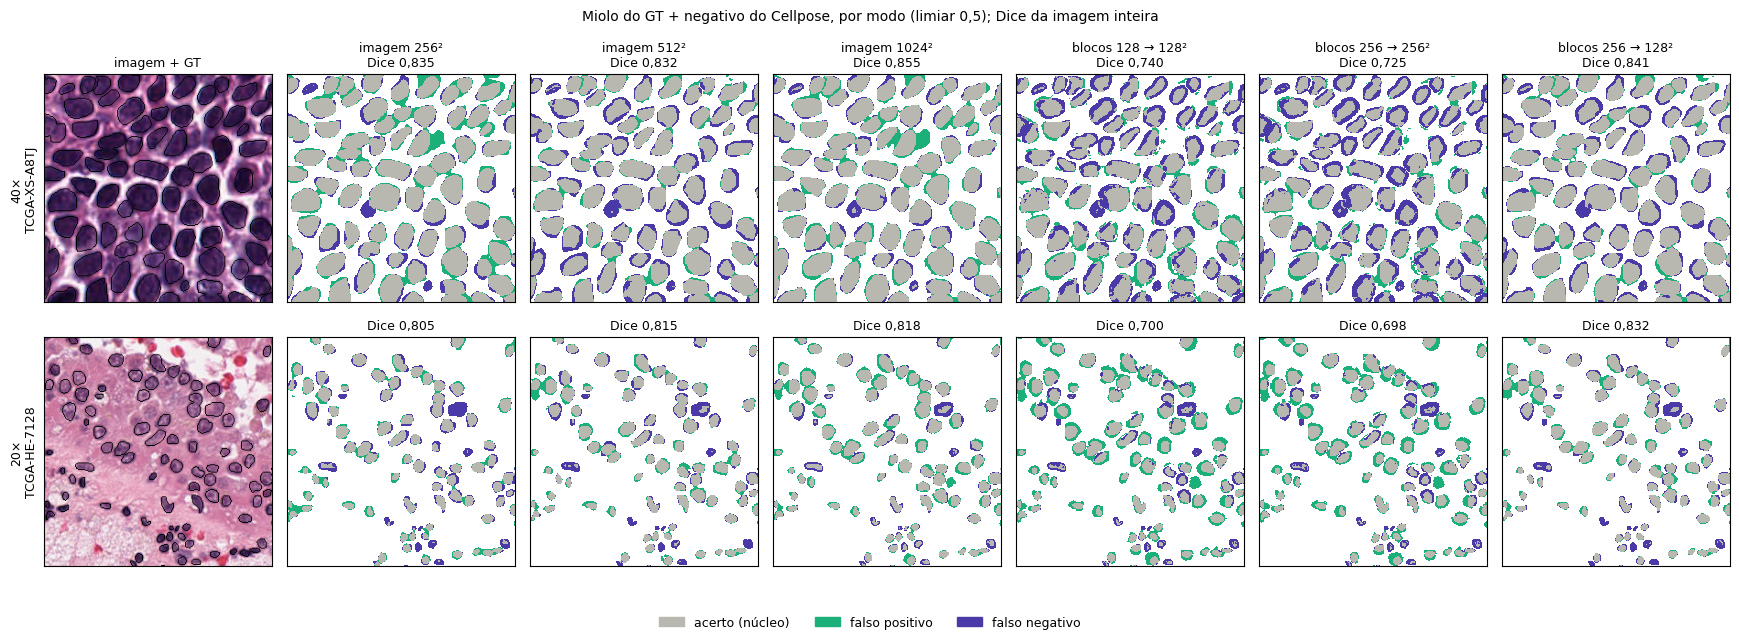

In [14]:
COR_VP = np.array([0xB8, 0xB7, 0xB0]) / 255
COR_FP = np.array([0x1B, 0xAF, 0x7A]) / 255
COR_FN = np.array([0x4A, 0x3A, 0xA7]) / 255
LADO = 250
FIG_IDS = {"40×": "TCGA-XS-A8TJ-01Z-00-DX1", "20×": "TCGA-HE-7128-01Z-00-DX1"}


def janela(gt, lado=LADO, passo=125):
    h, w = gt.shape
    cantos = [(y, x) for y in range(0, h - lado + 1, passo) for x in range(0, w - lado + 1, passo)]
    return max(cantos, key=lambda c: gt[c[0]:c[0] + lado, c[1]:c[1] + lado].sum())


def mapa_erro(pred, gt):
    out = np.ones(gt.shape + (3,))
    out[pred & gt] = COR_VP
    out[pred & ~gt] = COR_FP
    out[~pred & gt] = COR_FN
    return out


fig, axes = plt.subplots(len(FIG_IDS), len(MODOS) + 1, figsize=(2.5 * (len(MODOS) + 1), 3.2 * len(FIG_IDS)))
for linha, (nome, image_id) in enumerate(FIG_IDS.items()):
    s = samples[image_id]
    gt = s["ground_truth"] > 0
    y, x = janela(gt)
    fatia = (slice(y, y + LADO), slice(x, x + LADO))
    img = s["image"][fatia].astype(float) / 255
    img[find_boundaries(gt[fatia], mode="inner")] = 0
    axes[linha, 0].imshow(img)
    axes[linha, 0].set_title("imagem + GT" if linha == 0 else "", fontsize=9)
    m, neg = marcadores(s)["miolo"], negativos(s)["cp_fundo_r3"]
    for j, (modo, (bloco, entrada)) in enumerate(MODOS.items(), start=1):
        prob = segmentar(s["image"], m, neg, bloco, entrada)
        d = binary_metrics(prob, gt)["dice"]
        axes[linha, j].imshow(mapa_erro((prob >= 0.5)[fatia], gt[fatia]), interpolation="nearest")
        topo = modo + "\n" if linha == 0 else ""
        axes[linha, j].set_title(topo + f"Dice {d:.3f}".replace(".", ","), fontsize=9)
    for ax in axes[linha]:
        ax.set_xticks([]), ax.set_yticks([])
    axes[linha, 0].set_ylabel(f"{nome}\n{image_id[:12]}", fontsize=9)
fig.legend(handles=[Patch(color=COR_VP, label="acerto (núcleo)"), Patch(color=COR_FP, label="falso positivo"),
                    Patch(color=COR_FN, label="falso negativo")], loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Miolo do GT + negativo do Cellpose, por modo (limiar 0,5); Dice da imagem inteira", fontsize=10)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 7. Salvar (opcional)

In [15]:
if SALVAR_RESULTADOS:
    os.makedirs(OUTPUT_DIR, exist_ok=False)
    df.to_csv(os.path.join(OUTPUT_DIR, "por_imagem.csv.gz"), index=False)
    resumo.to_csv(os.path.join(OUTPUT_DIR, "resumo.csv"), index=False)
    fig.savefig(os.path.join(OUTPUT_DIR, "figura_modos.png"), dpi=100)
    config = {
        "modos": {k: list(v) for k, v in MODOS.items()}, "sobreposicao": SOBREPOSICAO, "limiares": LIMIARES,
        "imagens_20x": sorted(IMAGENS_20X), "tempo_medio_s": {m: float(np.mean(t)) for m, t in tempos.items()},
        "procedencia": provenance(),
    }
    with open(os.path.join(OUTPUT_DIR, "config.json"), "w") as fh:
        json.dump(config, fh, indent=2, ensure_ascii=False)
    print("Resultados em:", OUTPUT_DIR)
else:
    print("Nada salvo (SALVAR_RESULTADOS = False).")

Nada salvo (SALVAR_RESULTADOS = False).
